# 06 · de Broglie (1923–1924)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/06_de_broglie.ipynb)

Tính bước sóng vật chất, kiểm tra điều kiện Bohr, rồi phân biệt vận tốc pha và vận tốc nhóm. Chạy từ trên xuống; không cần tải dữ liệu.
*Calculate matter wavelengths, check Bohr's condition, then distinguish phase and group velocities. Run from top to bottom; no data downloads are needed.*


## 1. Sóng của mọi thứ / Everything has a wave

Dùng $\lambda=h/(mv)$ ở giới hạn phi tương đối tính. Kích thước electron ở đây là đường kính nguyên tử hydro, không phải bán kính nội tại của electron. Với electron qua 54 V, cũng dùng thang kích thước nguyên tử để so sánh.
*Use $\lambda=h/(mv)$ in the nonrelativistic limit. The electron's comparison size here is the hydrogen atom's diameter, not an intrinsic electron radius. The 54 V electron is also compared with the atomic scale.*


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import h, hbar, c, e

# Match the web simulation's constants and characteristic sizes.
m_e = 9.1093837015e-31
atomic_mass = 1.66053906660e-27
a0 = 5.29177210903e-11
alpha_c = 2.18769126364e6
ry_ev = 13.605693122994

def wavelength(mass, speed):
    return h / (mass * speed)

objects = [
    ("Electron in hydrogen", m_e, alpha_c, 1.06e-10),
    ("Silver atom (episode 5 oven)", 107.8682 * atomic_mass, 550, 2.9e-10),
    ("1 micrometre dust grain", 1.05e-15, 1e-3, 1e-6),
    ("Baseball", 0.145, 40, 0.074),
    ("Electron through 54 V", m_e, np.sqrt(2 * e * 54 / m_e), 1.06e-10),
]
print(f"{'Object':30s} {'Speed (m/s)':>13s} {'Wavelength (m)':>16s} {'Size / wavelength':>19s}")
for name, mass, speed, size in objects:
    lam = wavelength(mass, speed)
    print(f"{name:30s} {speed:13.5e} {lam:16.6e} {size / lam:19.6e}")
assert np.isclose(wavelength(m_e, alpha_c), 2 * np.pi * a0, rtol=1e-6, atol=0)
assert np.isclose(wavelength(m_e, objects[-1][2]), 1.67e-10, rtol=0.005, atol=0)
assert np.isclose(wavelength(0.145, 40), 1.142e-34, rtol=0.01, atol=0)


Object                           Speed (m/s)   Wavelength (m)   Size / wavelength
Electron in hydrogen             2.18769e+06     3.324918e-10        3.188048e-01
Silver atom (episode 5 oven)     5.50000e+02     6.725906e-12        4.311687e+01
1 micrometre dust grain          1.00000e-03     6.310543e-16        1.584650e+09
Baseball                         4.00000e+01     1.142426e-34        6.477444e+32
Electron through 54 V            4.35835e+06     1.668954e-10        6.351282e-01


## 2. Sóng trên quỹ đạo Coulomb / Waves on a Coulomb orbit

Với quỹ đạo tròn trong hydro: $v(r)=\alpha c\sqrt{a_0/r}$ và $N(r)=2\pi r/\lambda=\sqrt{r/a_0}$. Điều kiện $N=n$ cho $r=n^2a_0$ và $mvr=n\hbar$.
*For a circular hydrogen orbit, an integer number of wavelengths gives Bohr's radii and angular momenta.*

Dùng khối lượng hạt nhân vô hạn; `bohr.js` dùng khối lượng rút gọn, khác khoảng 0,05%. Các quỹ đạo và sóng quấn quanh vòng tròn là hình ảnh bán cổ điển, không phải orbital Schrödinger.
*Use infinite nuclear mass; `bohr.js` uses reduced mass, differing by about 0.05%. These circular orbits and wrapped waves are a semiclassical picture, not Schrödinger orbitals.*


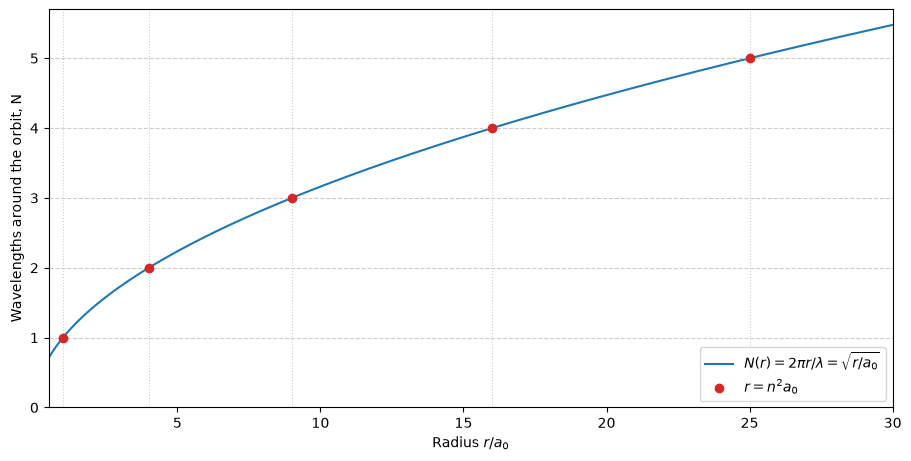

Bohr angular momentum check: m v r / (n hbar) = [1. 1. 1. 1. 1.]


In [2]:
def orbit_speed(radius):
    return alpha_c * np.sqrt(a0 / radius)

def turns(radius):
    return 2 * np.pi * radius / wavelength(m_e, orbit_speed(radius))

def orbit_energy(radius):
    return -ry_ev * a0 / radius

n = np.arange(1, 6)
radii = n**2 * a0
assert np.allclose(m_e * orbit_speed(radii) * radii / (n * hbar), 1, rtol=1e-9, atol=0)
x = np.linspace(0.5, 30, 3000)
assert np.allclose(turns(x * a0), np.sqrt(x), rtol=1e-9, atol=0)
assert np.isclose(orbit_energy(4 * a0), -ry_ev / 4, rtol=0, atol=1e-12)
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.plot(x, turns(x * a0), label=r"$N(r)=2\pi r/\lambda=\sqrt{r/a_0}$")
for level in n:
    ax.axhline(level, color="0.8", lw=0.8, ls="--")
    ax.axvline(level**2, color="0.8", lw=0.8, ls=":")
ax.scatter(n**2, n, color="tab:red", zorder=3, label=r"$r=n^2 a_0$")
ax.set(xlim=(0.5, 30), ylim=(0, 5.7), xlabel=r"Radius $r/a_0$", ylabel="Wavelengths around the orbit, N")
ax.legend()
plt.show()
print("Bohr angular momentum check: m v r / (n hbar) =", m_e * orbit_speed(radii) * radii / (n * hbar))


## 3. Chồng sáu vòng / Superposing six laps

Sau $K$ vòng, biên độ tương đối là $A=\left|\sin(\pi NK)/(K\sin(\pi N))\right|$, lấy giới hạn $A=1$ tại $N$ nguyên. Đây là biên độ, không phải cường độ $A^2$; các đỉnh cao bằng 1 nằm đúng tại $r=n^2a_0$.
*After $K$ laps, the relative amplitude is the normalised Dirichlet kernel above. Its unit-height peaks occur exactly at Bohr's radii. This is amplitude, not intensity $A^2$.*

Tổng hữu hạn còn các đỉnh phụ; đồ thị minh hoạ điều kiện nối pha, không mô tả quá trình phân rã theo thời gian của nguyên tử thật.
*The finite sum also has smaller side lobes; this illustrates phase closure rather than the time evolution of a real atom's decay.*


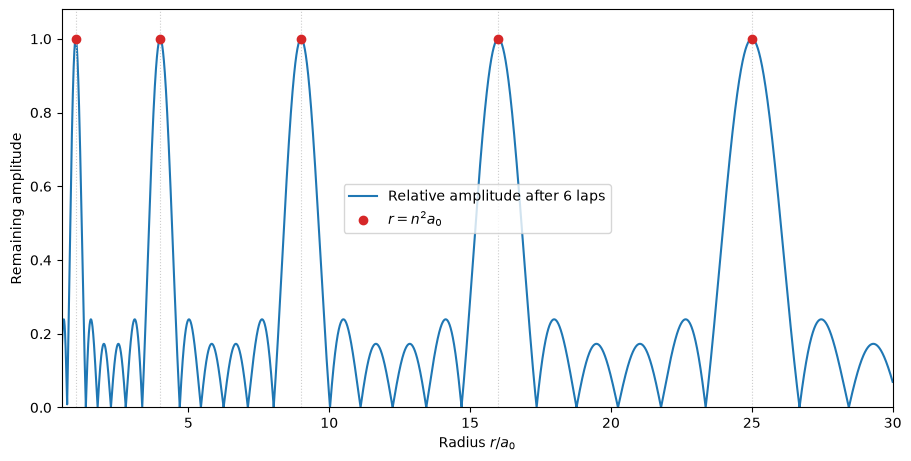

Exact-fit amplitudes: [1. 1. 1. 1. 1.]


In [3]:
def residual(N, K=6):
    N = np.asarray(N, dtype=float)
    # Reduce the phase and use sinc to avoid cancellation near integer turns.
    delta = N - np.rint(N)
    return np.abs(np.sinc(K * delta) / np.sinc(delta))

# Include the exact Bohr radii in the plot grid.
x = np.unique(np.r_[np.linspace(0.5, 30, 6000), n**2])
assert np.allclose(residual(turns(radii)), 1, rtol=0, atol=1e-12)
assert residual(2.5) < 1e-9
assert 0 < residual(2.9) < 1
# Independently sum the six complex amplitudes.
trial_N = np.array([0.8, 1, 2.5, 2.9, 3, 5.4])
direct = np.abs(np.mean(np.exp(2j * np.pi * trial_N[:, None] * np.arange(6)), axis=1))
assert np.allclose(residual(trial_N), direct, rtol=0, atol=1e-12)
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.plot(x, residual(turns(x * a0)), label="Relative amplitude after 6 laps")
for level in n:
    ax.axvline(level**2, color="0.8", lw=0.8, ls=":")
ax.scatter(n**2, np.ones_like(n), color="tab:red", zorder=3, label=r"$r=n^2 a_0$")
ax.set(xlim=(0.5, 30), ylim=(0, 1.08), xlabel=r"Radius $r/a_0$", ylabel="Remaining amplitude")
ax.legend()
plt.show()
print("Exact-fit amplitudes:", residual(turns(radii)))


## 4. Con đường của de Broglie (1923) / de Broglie's route (1923)

Đồng hồ nội tại ở trạng thái nghỉ có tần số $\nu_0=mc^2/h$. Khi chuyển động, $E=\gamma mc^2=h\nu$, $p=\gamma mv$. Với $\omega=2\pi\nu$ và $k=p/\hbar$, vận tốc pha $V=\omega/k=c^2/v>c$ còn vận tốc nhóm $d\omega/dk=v$.
*The rest-frame internal clock has frequency $\nu_0=mc^2/h$. Energy and momentum give a phase velocity above light speed, while the group velocity equals the particle velocity.*

Từ $\omega(k)=\sqrt{(mc^2/\hbar)^2+c^2k^2}$, tính đạo hàm số để kiểm tra vận tốc nhóm. Sau đó $\lambda=V/\nu=h/(\gamma mv)=h/p$. Vận tốc pha không phải tốc độ truyền tín hiệu; tần số sóng $\gamma\nu_0$ cũng khác nhịp đồng hồ chuyển động $\nu_0/\gamma$.
*Numerically differentiate the dispersion relation to check the group velocity, then recover the wavelength. Phase velocity is not signal speed; the wave frequency $\gamma\nu_0$ differs from the moving clock rate $\nu_0/\gamma$.*


In [4]:
nu0 = m_e * c**2 / h

def omega(k):
    return np.sqrt((m_e * c**2 / hbar)**2 + c**2 * k**2)

print(f"Electron rest clock frequency: {nu0:.9e} Hz")
print(f"{'v/c':>6s} {'gamma':>12s} {'nu (Hz)':>16s} {'V/c':>12s} {'Group v/c':>14s} {'lambda (m)':>16s}")
for beta in [0.01, 0.5]:
    speed = beta * c
    gamma = 1 / np.sqrt(1 - beta**2)
    energy = gamma * m_e * c**2
    momentum = gamma * m_e * speed
    nu = energy / h
    k = momentum / hbar
    phase_velocity = omega(k) / k
    dk = k * 1e-3
    group_velocity = (omega(k + dk) - omega(k - dk)) / (2 * dk)
    lam = phase_velocity / nu
    assert np.isclose(omega(k), 2 * np.pi * nu, rtol=1e-12, atol=0)
    assert phase_velocity > c
    assert np.isclose(phase_velocity, c**2 / speed, rtol=1e-12, atol=0)
    assert np.isclose(group_velocity, speed, rtol=1e-6, atol=0)
    assert np.isclose(lam, h / (gamma * m_e * speed), rtol=1e-12, atol=0)
    assert np.isclose(lam, h / momentum, rtol=1e-12, atol=0)
    # Along the particle's path, the wave phase advances at the dilated clock rate.
    assert np.isclose(nu - speed / lam, nu0 / gamma, rtol=1e-12, atol=0)
    print(f"{beta:6.2f} {gamma:12.9f} {nu:16.9e} {phase_velocity / c:12.6f} {group_velocity / c:14.9f} {lam:16.9e}")
print("All phase, group velocity and wavelength checks passed.")


Electron rest clock frequency: 1.235589964e+20 Hz
   v/c        gamma          nu (Hz)          V/c      Group v/c       lambda (m)
  0.01  1.000050004  1.235651748e+20   100.000000    0.010000000  2.426188920e-10
  0.50  1.154700538  1.426736396e+20     2.000000    0.499999953  4.202492608e-12
All phase, group velocity and wavelength checks passed.
